In [1]:

from pathlib import Path
import zipfile

zip_path = Path("DeepPCB-master.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(".")

print("DeepPCB extracted successfully!")



DeepPCB extracted successfully!


In [2]:

from pathlib import Path

image = Path("DeepPCB-master/PCBData/group00041/00041/00041000_test.jpg")

print("Image found:", image.exists())



Image found: True


In [3]:

from pathlib import Path

dataset = Path("DeepPCB-master/PCBData")

print("Dataset found:", dataset.exists())

images = list(dataset.rglob("*_test.jpg"))
print("Number of test images:", len(images))

if images:
    print("Example image:", images[0])



Dataset found: True
Number of test images: 1500
Example image: DeepPCB-master\PCBData\group92000\92000\92000000_test.jpg


Image loaded: True
Image shape: (640, 640)


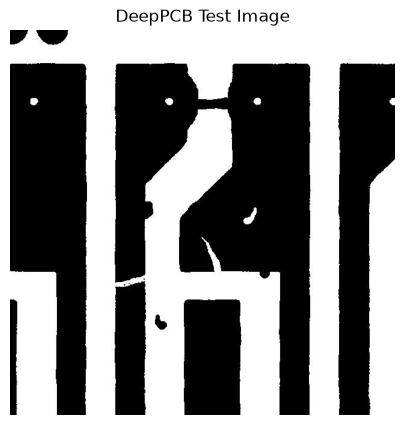

In [4]:

import cv2
import matplotlib.pyplot as plt

image_path = str(images[0])

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

print("Image loaded:", image is not None)

if image is not None:
    print("Image shape:", image.shape)

    plt.figure(figsize=(5, 5))
    plt.imshow(image, cmap="gray")
    plt.title("DeepPCB Test Image")
    plt.axis("off")
    plt.show()



In [5]:

from pathlib import Path

code = Path("detection.py").read_text(encoding="utf-8-sig")

print(code[:12000])


import cv2

def find_boxes(binary, min_area=100, pad=0):
    # Find contours in the binary image
    contours, _ = cv2.findContours(
        binary.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []
    height, width = binary.shape[:2]

    for contour in contours:
        # Ignore small regions
        area = cv2.contourArea(contour)

        if area >= min_area:
            # Get bounding box coordinates
            x, y, w, h = cv2.boundingRect(contour)

            # Add padding without exceeding image boundaries
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(width, x + w + pad)
            y2 = min(height, y + h + pad)

            boxes.append((x1, y1, x2, y2))

    return boxes



In [6]:

from pathlib import Path

code = Path("evaluate (1).py").read_text(
    encoding="utf-8-sig"
)

print(code[:20000])


# -*- coding: utf-8 -*-
"""Untitled0.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1ovqTM3TyEtenVhM_V_CmpnJrfkrZNBvu
"""

# ARTI 403 — Group 2
#  Evaluation Metrics for PCB Defect Detection
# My contribution:
# I evaluate the bounding boxes produced by the PCB defect detector.
# I compare them with the DeepPCB ground-truth boxes using IoU and
# calculate TP, FP, FN, precision, recall, and F1.
# I also report localization recall separately for Open and Short defects.

IOU_THRESHOLD = 0.33


def iou(box_a, box_b):
    """Calculate the intersection over union of two bounding boxes."""
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    width = max(0, min(ax2, bx2) - max(ax1, bx1))
    height = max(0, min(ay2, by2) - max(ay1, by1))
    intersection = width * height

    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union = area_a + area_b - intersection

    return intersectio

In [7]:

from pathlib import Path

code = Path("preprocess (1).py").read_text(
    encoding="utf-8-sig"
)

print(code[:20000])


"""
Role 2 - Preprocessing & Subtraction
ARTI 403 - Group 2 - Automated PCB Defect Detection

Interface (agreed between roles):
    difference(test, temp, blur, k) -> diff image

    test  : defective image (BGR or grayscale, numpy array)
    temp  : defect-free template image (same size as test)
    blur  : "none" | "gaussian" | "median"
    k     : filter size (odd number, e.g. 3, 5, 7). Ignored when blur="none".

Returns a single-channel uint8 image where bright pixels show
where the test image differs from the template (possible defects).
"""

import cv2

# Settings that Role 6 can change in experiments
BLUR_OPTIONS = ("none", "gaussian", "median")
DEFAULT_BLUR = "gaussian"
DEFAULT_K = 5


def to_gray(img):
    """Convert to grayscale if the image has 3 channels."""
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img


def denoise(gray, blur=DEFAULT_BLUR, k=DEFAULT_K):
    """Apply the chosen noise-removal filter to a grayscale image."""
    bl

Test image found: True
Template found: True
Number of predicted boxes: 432


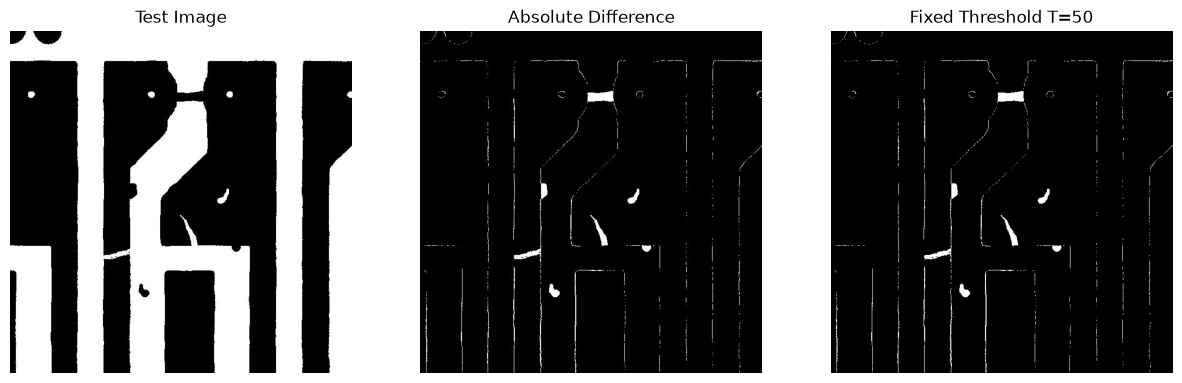

In [8]:

import cv2
import runpy
import matplotlib.pyplot as plt
from pathlib import Path

# Load your teammates' functions
preprocess = runpy.run_path("preprocess (1).py")
detector = runpy.run_path("detection.py")

difference = preprocess["difference"]
find_boxes = detector["find_boxes"]

# Select one PCB image pair
test_path = images[0]
temp_path = Path(
    str(test_path).replace("_test.jpg", "_temp.jpg")
)

test_img = cv2.imread(str(test_path))
temp_img = cv2.imread(str(temp_path))

print("Test image found:", test_img is not None)
print("Template found:", temp_img is not None)

if test_img is None or temp_img is None:
    raise FileNotFoundError("A PCB image pair is missing.")

# Baseline: no filtering
diff = difference(
    test_img,
    temp_img,
    blur="none",
    k=5
)

# Fixed threshold T = 50
_, binary = cv2.threshold(
    diff, 50, 255, cv2.THRESH_BINARY
)

# Detect bounding boxes
boxes = find_boxes(
    binary,
    min_area=0,
    pad=0
)

print("Number of predicted boxes:", len(boxes))

# Display the processing results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(test_img, cmap=None)
axes[0].set_title("Test Image")

axes[1].imshow(diff, cmap="gray")
axes[1].set_title("Absolute Difference")

axes[2].imshow(binary, cmap="gray")
axes[2].set_title("Fixed Threshold T=50")

for ax in axes:
    ax.axis("off")

plt.show()


In [9]:

from pathlib import Path

# Show the selected test image
print("Test image:", test_path)

# Find its corresponding annotation file
image_id = test_path.stem.replace("_test", "")

annotation_files = list(
    Path("DeepPCB-master").rglob(image_id + ".txt")
)

print("Matching annotation files:", len(annotation_files))

for file in annotation_files:
    print("Annotation:", file)
    print("Contents:")
    print(file.read_text(encoding="utf-8"))


Test image: DeepPCB-master\PCBData\group92000\92000\92000000_test.jpg
Matching annotation files: 1
Annotation: DeepPCB-master\PCBData\group92000\92000_not\92000000.txt
Contents:
162 397 243 436 1
296 102 377 141 2
308 334 360 415 3
207 275 247 323 4
405 386 441 422 4
378 285 419 332 6
231 463 270 507 5



In [10]:

import runpy

# Load your teammate's evaluation functions
evaluation = runpy.run_path("evaluate (1).py")
evaluate = evaluation["evaluate"]
count_matches = evaluation["count_matches"]

# Read the annotation file found earlier
annotation_path = annotation_files[0]

gt = []

with open(annotation_path, "r") as file:
    for line in file:
        values = list(map(int, line.strip().split()))

        if len(values) == 5:
            gt.append(tuple(values))

# Evaluate the baseline predictions
results = evaluate(boxes, gt)

print("Ground-truth boxes:", len(gt))
print("Predicted boxes:", len(boxes))

print("True Positives:", results["TP"])
print("False Positives:", results["FP"])
print("False Negatives:", results["FN"])

print(f"Precision: {results['P'] * 100:.2f}%")
print(f"Recall: {results['R'] * 100:.2f}%")
print(f"F1-score: {results['F1'] * 100:.2f}%")


Ground-truth boxes: 7
Predicted boxes: 432
True Positives: 1
False Positives: 431
False Negatives: 1
Precision: 0.23%
Recall: 50.00%
F1-score: 0.46%


In [11]:

from pathlib import Path

root = Path("DeepPCB-master")

# Find text files that may define dataset splits
split_files = [
    p for p in root.rglob("*.txt")
    if "train" in p.name.lower()
    or "test" in p.name.lower()
    or "val" in p.name.lower()
]

print("Possible split files:")

for p in split_files[:30]:
    print(p)

print("Total possible split files:", len(split_files))


Possible split files:
DeepPCB-master\PCBData\test.txt
DeepPCB-master\PCBData\trainval.txt
DeepPCB-master\tools\examples\test.txt
Total possible split files: 3


In [13]:
from pathlib import Path

root = Path("DeepPCB-master/PCBData")

train_file = root / "trainval.txt"
test_file = root / "test.txt"

train_lines = [
    line.strip()
    for line in train_file.read_text().splitlines()
    if line.strip()
]

test_lines = [
    line.strip()
    for line in test_file.read_text().splitlines()
    if line.strip()
]

print("Development images:", len(train_lines))
print("Test images:", len(test_lines))

print("First 3 Development entries:")
for line in train_lines[:3]:
    print(line)

print("First 3 Test entries:")
for line in test_lines[:3]:
    print(line)


Development images: 1000
Test images: 500
First 3 Development entries:
group20085/20085/20085000.jpg group20085/20085_not/20085000.txt
group20085/20085/20085001.jpg group20085/20085_not/20085001.txt
group20085/20085/20085002.jpg group20085/20085_not/20085002.txt
First 3 Test entries:
group20085/20085/20085291.jpg group20085/20085_not/20085291.txt
group20085/20085/20085292.jpg group20085/20085_not/20085292.txt
group20085/20085/20085293.jpg group20085/20085_not/20085293.txt


In [15]:

import cv2
import runpy
import pandas as pd
from pathlib import Path

# Load teammates' functions
preprocess = runpy.run_path("preprocess (1).py")
detector = runpy.run_path("detection.py")
evaluation = runpy.run_path("evaluate (1).py")

difference = preprocess["difference"]
find_boxes = detector["find_boxes"]
evaluate_dataset = evaluation["evaluate_dataset"]

root = Path("DeepPCB-master/PCBData")

def run_baseline(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        # Build correct DeepPCB image paths
        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        # Read image pair
        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError(
                f"Missing image: {test_path} or {temp_path}"
            )

        if not annotation_path.exists():
            raise FileNotFoundError(
                f"Missing annotation: {annotation_path}"
            )

        # Baseline: no filtering
        diff = difference(
            test_img,
            temp_img,
            blur="none",
            k=5
        )

        # Fixed threshold
        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        # Bounding boxes
        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        # Read ground truth
        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 100 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


# Run on Development only
baseline_results = run_baseline(train_lines)

combined = baseline_results["Combined"]

print("\nBASELINE DEVELOPMENT RESULTS")
print("TP:", combined["TP"])
print("FP:", combined["FP"])
print("FN:", combined["FN"])

print(f"Precision: {combined['P'] * 100:.2f}%")
print(f"Recall: {combined['R'] * 100:.2f}%")
print(f"F1-score: {combined['F1'] * 100:.2f}%")

# Save results
baseline_row = pd.DataFrame([{
    "Configuration": "Baseline",
    "Precision": combined["P"],
    "Recall": combined["R"],
    "F1": combined["F1"],
    "TP": combined["TP"],
    "FP": combined["FP"],
    "FN": combined["FN"]
}])

baseline_row.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nSaved: baseline_development.csv")



Processed 100 images
Processed 200 images
Processed 300 images
Processed 400 images
Processed 500 images
Processed 600 images
Processed 700 images
Processed 800 images
Processed 900 images
Processed 1000 images

BASELINE DEVELOPMENT RESULTS
TP: 488
FP: 473021
FN: 1823
Precision: 0.10%
Recall: 21.12%
F1-score: 0.21%

Saved: baseline_development.csv


In [16]:

import pandas as pd

def run_gaussian(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="gaussian",
            k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []
        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()
                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


gaussian_results = run_gaussian(train_lines)
g = gaussian_results["Combined"]

print("\nGAUSSIAN DEVELOPMENT RESULTS")
print("TP:", g["TP"])
print("FP:", g["FP"])
print("FN:", g["FN"])

print(f"Precision: {g['P']*100:.2f}%")
print(f"Recall: {g['R']*100:.2f}%")
print(f"F1-score: {g['F1']*100:.2f}%")

# Add the new experiment to your CSV file
previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Gaussian blur k=5",
    "Precision": g["P"],
    "Recall": g["R"],
    "F1": g["F1"],
    "TP": g["TP"],
    "FP": g["FP"],
    "FN": g["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nGaussian experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

GAUSSIAN DEVELOPMENT RESULTS
TP: 522
FP: 244258
FN: 1789
Precision: 0.21%
Recall: 22.59%
F1-score: 0.42%

Gaussian experiment saved!


In [17]:

def run_median(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="median",
            k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


median_results = run_median(train_lines)
m = median_results["Combined"]

print("\nMEDIAN DEVELOPMENT RESULTS")
print("TP:", m["TP"])
print("FP:", m["FP"])
print("FN:", m["FN"])

print(f"Precision: {m['P']*100:.2f}%")
print(f"Recall: {m['R']*100:.2f}%")
print(f"F1-score: {m['F1']*100:.2f}%")

# Add Median results to existing CSV
previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Median blur k=5",
    "Precision": m["P"],
    "Recall": m["R"],
    "F1": m["F1"],
    "TP": m["TP"],
    "FP": m["FP"],
    "FN": m["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nMedian experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

MEDIAN DEVELOPMENT RESULTS
TP: 560
FP: 293800
FN: 1751
Precision: 0.19%
Recall: 24.23%
F1-score: 0.38%

Median experiment saved!


In [18]:

def run_otsu(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="none",
            k=5
        )

        # Otsu thresholding
        _, binary = cv2.threshold(
            diff,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


otsu_results = run_otsu(train_lines)
o = otsu_results["Combined"]

print("\nOTSU DEVELOPMENT RESULTS")
print("TP:", o["TP"])
print("FP:", o["FP"])
print("FN:", o["FN"])

print(f"Precision: {o['P']*100:.2f}%")
print(f"Recall: {o['R']*100:.2f}%")
print(f"F1-score: {o['F1']*100:.2f}%")

previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Otsu thresholding",
    "Precision": o["P"],
    "Recall": o["R"],
    "F1": o["F1"],
    "TP": o["TP"],
    "FP": o["FP"],
    "FN": o["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nOtsu experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

OTSU DEVELOPMENT RESULTS
TP: 488
FP: 472480
FN: 1823
Precision: 0.10%
Recall: 21.12%
F1-score: 0.21%

Otsu experiment saved!


In [19]:

def run_adaptive(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img,
            temp_img,
            blur="none",
            k=5
        )

        # Adaptive Gaussian Thresholding
        binary = cv2.adaptiveThreshold(
            diff,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            31,
            -25
        )

        boxes = find_boxes(
            binary,
            min_area=0,
            pad=0
        )

        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


adaptive_results = run_adaptive(train_lines)
a = adaptive_results["Combined"]

print("\nADAPTIVE DEVELOPMENT RESULTS")
print("TP:", a["TP"])
print("FP:", a["FP"])
print("FN:", a["FN"])

print(f"Precision: {a['P']*100:.2f}%")
print(f"Recall: {a['R']*100:.2f}%")
print(f"F1-score: {a['F1']*100:.2f}%")

previous = pd.read_csv("baseline_development.csv")

new_row = pd.DataFrame([{
    "Configuration": "Adaptive thresholding",
    "Precision": a["P"],
    "Recall": a["R"],
    "F1": a["F1"],
    "TP": a["TP"],
    "FP": a["FP"],
    "FN": a["FN"]
}])

updated = pd.concat(
    [previous, new_row],
    ignore_index=True
)

updated.to_csv(
    "baseline_development.csv",
    index=False
)

print("\nAdaptive experiment saved!")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

ADAPTIVE DEVELOPMENT RESULTS
TP: 488
FP: 492590
FN: 1823
Precision: 0.10%
Recall: 21.12%
F1-score: 0.20%

Adaptive experiment saved!


In [20]:

import cv2
import pandas as pd
import numpy as np

def run_morphology(split_lines, operation, kernel_size):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        # Same baseline preprocessing
        diff = difference(
            test_img, temp_img,
            blur="none", k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        kernel = np.ones(
            (kernel_size, kernel_size), np.uint8
        )

        if operation == "opening":
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_OPEN, kernel
            )

        elif operation == "closing":
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_CLOSE, kernel
            )

        elif operation == "opening_closing":
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_OPEN, kernel
            )
            binary = cv2.morphologyEx(
                binary, cv2.MORPH_CLOSE, kernel
            )

        else:
            raise ValueError("Invalid operation")

        boxes = find_boxes(
            binary, min_area=0, pad=0
        )

        gt = []
        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()
                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

    return evaluate_dataset(samples)["Combined"]


experiments = []

for operation in ["opening", "closing", "opening_closing"]:
    for k in [3, 5, 7]:

        print(f"Running {operation}, kernel={k}...")

        result = run_morphology(
            train_lines, operation, k
        )

        experiments.append({
            "Configuration": f"{operation} {k}x{k}",
            "Precision": result["P"],
            "Recall": result["R"],
            "F1": result["F1"],
            "TP": result["TP"],
            "FP": result["FP"],
            "FN": result["FN"]
        })

        print(
            f"F1: {result['F1']*100:.2f}% | "
            f"Precision: {result['P']*100:.2f}% | "
            f"Recall: {result['R']*100:.2f}%"
        )

# Save morphology results separately
morphology_df = pd.DataFrame(experiments)

morphology_df.to_csv(
    "morphology_development.csv",
    index=False
)

# Merge with previous experiments
previous = pd.read_csv("baseline_development.csv")

updated = pd.concat(
    [previous, morphology_df],
    ignore_index=True
)

updated.to_csv(
    "results_development.csv",
    index=False
)

print("\nAll morphology experiments completed!")
print("Saved: results_development.csv")

display(
    morphology_df[
        ["Configuration", "Precision", "Recall", "F1"]
    ]
)


Running opening, kernel=3...
F1: 1.35% | Precision: 0.75% | Recall: 7.10%
Running opening, kernel=5...
F1: 1.57% | Precision: 1.04% | Recall: 3.20%
Running opening, kernel=7...
F1: 0.97% | Precision: 0.83% | Recall: 1.17%
Running closing, kernel=3...
F1: 0.29% | Precision: 0.15% | Recall: 23.67%
Running closing, kernel=5...
F1: 0.36% | Precision: 0.18% | Recall: 25.62%
Running closing, kernel=7...
F1: 0.44% | Precision: 0.22% | Recall: 25.92%
Running opening_closing, kernel=3...
F1: 1.74% | Precision: 0.99% | Recall: 7.62%
Running opening_closing, kernel=5...
F1: 1.97% | Precision: 1.33% | Recall: 3.81%
Running opening_closing, kernel=7...
F1: 1.23% | Precision: 1.08% | Recall: 1.43%

All morphology experiments completed!
Saved: results_development.csv


,Configuration,Precision,Recall,F1
0,opening 3x3,0.007474,0.070965,0.013523
1,opening 5x5,0.010379,0.032021,0.015676
2,opening 7x7,0.008331,0.011683,0.009726
3,closing 3x3,0.001460,0.236694,0.002903
4,closing 5x5,0.001829,0.256166,0.003633
5,closing 7x7,0.002219,0.259195,0.004401
6,opening_closing 3x3,0.009851,0.076158,0.017445
7,opening_closing 5x5,0.013265,0.038079,0.019676
8,opening_closing 7x7,0.010848,0.014280,0.012330


In [21]:

import cv2
import pandas as pd
from pathlib import Path

def run_min_area(split_lines, min_area):
    samples = []

    for line in split_lines:
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )
        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )
        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError("Missing image pair")

        diff = difference(
            test_img, temp_img,
            blur="none", k=5
        )

        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        boxes = find_boxes(
            binary,
            min_area=min_area,
            pad=0
        )

        gt = []
        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()
                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

    return evaluate_dataset(samples)["Combined"]


area_results = []

for area in [5, 10, 20, 100, 150, 200, 300]:
    print(f"Running min_area={area}...")

    result = run_min_area(train_lines, area)

    area_results.append({
        "Configuration": f"Minimum contour area {area} px2",
        "Precision": result["P"],
        "Recall": result["R"],
        "F1": result["F1"],
        "TP": result["TP"],
        "FP": result["FP"],
        "FN": result["FN"]
    })

    print(
        f"Precision: {result['P']*100:.2f}% | "
        f"Recall: {result['R']*100:.2f}% | "
        f"F1: {result['F1']*100:.2f}%"
    )


area_df = pd.DataFrame(area_results)

area_df.to_csv(
    "minimum_area_development.csv",
    index=False
)

# Merge with previous experiments
previous = pd.read_csv("results_development.csv")

updated = pd.concat(
    [previous, area_df],
    ignore_index=True
)

updated.to_csv(
    "results_development.csv",
    index=False
)

print("\nMinimum-area experiments completed!")
print("Saved: results_development.csv")

display(area_df)


Running min_area=5...
Precision: 1.71% | Recall: 21.12% | F1: 3.17%
Running min_area=10...
Precision: 2.06% | Recall: 21.12% | F1: 3.75%
Running min_area=20...
Precision: 2.60% | Recall: 21.07% | F1: 4.63%
Running min_area=100...
Precision: 6.00% | Recall: 17.52% | F1: 8.94%
Running min_area=150...
Precision: 7.61% | Recall: 14.41% | F1: 9.96%
Running min_area=200...
Precision: 9.09% | Recall: 12.55% | F1: 10.54%
Running min_area=300...
Precision: 10.81% | Recall: 8.70% | F1: 9.64%

Minimum-area experiments completed!
Saved: results_development.csv


,Configuration,Precision,Recall,F1,TP,FP,FN
0,Minimum contour area 5 px2,0.017141,0.211164,0.031708,488,27982,1823
1,Minimum contour area 10 px2,0.020566,0.211164,0.037481,488,23241,1823
2,Minimum contour area 20 px2,0.026004,0.210731,0.046295,487,18241,1824
3,Minimum contour area 100 px2,0.059991,0.175249,0.089384,405,6346,1906
4,Minimum contour area 150 px2,0.076080,0.144093,0.099581,333,4044,1978
5,Minimum contour area 200 px2,0.090909,0.125487,0.105435,290,2900,2021
6,Minimum contour area 300 px2,0.108123,0.086975,0.096403,201,1658,2110


In [22]:

import pandas as pd

# Final configuration selected using Development
final_area = 200

# Evaluate on the held-out Test split
final_results = run_min_area(test_lines, final_area)

print("\nFINAL TEST RESULTS")
print("Configuration: Minimum contour area = 200 px2")
print("TP:", final_results["TP"])
print("FP:", final_results["FP"])
print("FN:", final_results["FN"])

print(f"Precision: {final_results['P'] * 100:.2f}%")
print(f"Recall: {final_results['R'] * 100:.2f}%")
print(f"F1-score: {final_results['F1'] * 100:.2f}%")

# Save final test results
final_df = pd.DataFrame([{
    "Configuration": "Minimum contour area 200 px2",
    "Split": "Test",
    "Precision": final_results["P"],
    "Recall": final_results["R"],
    "F1": final_results["F1"],
    "TP": final_results["TP"],
    "FP": final_results["FP"],
    "FN": final_results["FN"]
}])

final_df.to_csv("final_test_results.csv", index=False)

print("\nSaved: final_test_results.csv")



FINAL TEST RESULTS
Configuration: Minimum contour area = 200 px2
TP: 115
FP: 1797
FN: 1022
Precision: 6.01%
Recall: 10.11%
F1-score: 7.54%

Saved: final_test_results.csv


In [23]:

import cv2
import numpy as np
import pandas as pd

def run_combined(split_lines):
    samples = []

    for index, line in enumerate(split_lines):
        image_rel, annotation_rel = line.split()

        base_path = root / image_rel

        test_path = base_path.with_name(
            base_path.stem + "_test.jpg"
        )

        temp_path = base_path.with_name(
            base_path.stem + "_temp.jpg"
        )

        annotation_path = root / annotation_rel

        test_img = cv2.imread(str(test_path))
        temp_img = cv2.imread(str(temp_path))

        if test_img is None or temp_img is None:
            raise FileNotFoundError(
                f"Missing image pair: {test_path}"
            )

        # Step 1: Gaussian filtering and subtraction
        diff = difference(
            test_img,
            temp_img,
            blur="gaussian",
            k=5
        )

        # Step 2: Fixed threshold
        _, binary = cv2.threshold(
            diff, 50, 255, cv2.THRESH_BINARY
        )

        # Step 3: Opening and Closing
        kernel = np.ones((3, 3), np.uint8)

        binary = cv2.morphologyEx(
            binary, cv2.MORPH_OPEN, kernel
        )

        binary = cv2.morphologyEx(
            binary, cv2.MORPH_CLOSE, kernel
        )

        # Step 4: Minimum contour area
        boxes = find_boxes(
            binary,
            min_area=200,
            pad=0
        )

        # Step 5: Ground truth
        gt = []

        with open(annotation_path, "r") as file:
            for annotation in file:
                values = annotation.strip().split()

                if len(values) == 5:
                    gt.append(tuple(map(int, values)))

        samples.append((boxes, gt))

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1} images")

    return evaluate_dataset(samples)


combined_results = run_combined(train_lines)
c = combined_results["Combined"]

print("\nCOMBINED DEVELOPMENT RESULTS")
print("TP:", c["TP"])
print("FP:", c["FP"])
print("FN:", c["FN"])

print(f"Precision: {c['P'] * 100:.2f}%")
print(f"Recall: {c['R'] * 100:.2f}%")
print(f"F1-score: {c['F1'] * 100:.2f}%")

combined_df = pd.DataFrame([{
    "Configuration": "Combined Gaussian5 OpenClose3 Area200",
    "Precision": c["P"],
    "Recall": c["R"],
    "F1": c["F1"],
    "TP": c["TP"],
    "FP": c["FP"],
    "FN": c["FN"]
}])

combined_df.to_csv(
    "combined_development.csv",
    index=False
)

print("\nSaved: combined_development.csv")


Processed 200 images
Processed 400 images
Processed 600 images
Processed 800 images
Processed 1000 images

COMBINED DEVELOPMENT RESULTS
TP: 417
FP: 7807
FN: 1894
Precision: 5.07%
Recall: 18.04%
F1-score: 7.92%

Saved: combined_development.csv


In [24]:

import pandas as pd

# Load 21 completed experiments
development = pd.read_csv("results_development.csv")

# Load the additional combined experiment
combined = pd.read_csv("combined_development.csv")

# Add Combined only if it is not already present
development = development[
    ~development["Configuration"].str.startswith(
        "Combined Gaussian5", na=False
    )
]

all_results = pd.concat(
    [development, combined],
    ignore_index=True
)

# Sort configurations by F1-score
all_results = all_results.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

# Save complete experiment table
all_results.to_csv(
    "role6_development_final.csv",
    index=False
)

print("Total experiments:", len(all_results))
print("\nTop 10 configurations:")

display(
    all_results[
        ["Configuration", "Precision", "Recall", "F1"]
    ].head(10).style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

print("\nSaved: role6_development_final.csv")


Total experiments: 22

Top 10 configurations:


,Configuration,Precision,Recall,F1
0,Minimum contour area 200 px2,9.09%,12.55%,10.54%
1,Minimum contour area 150 px2,7.61%,14.41%,9.96%
2,Minimum contour area 300 px2,10.81%,8.70%,9.64%
3,Minimum contour area 100 px2,6.00%,17.52%,8.94%
4,Combined Gaussian5 OpenClose3 Area200,5.07%,18.04%,7.92%
5,Minimum contour area 20 px2,2.60%,21.07%,4.63%
6,Minimum contour area 10 px2,2.06%,21.12%,3.75%
7,Minimum contour area 5 px2,1.71%,21.12%,3.17%
8,opening_closing 5x5,1.33%,3.81%,1.97%
9,opening_closing 3x3,0.99%,7.62%,1.74%



Saved: role6_development_final.csv


In [25]:

from pathlib import Path
import pandas as pd

files = [
    "baseline_development.csv",
    "morphology_development.csv",
    "minimum_area_development.csv",
    "combined_development.csv",
    "role6_development_final.csv",
    "final_test_results.csv"
]

print("ROLE 6 FILE CHECK")
print("-" * 35)

for name in files:
    if Path(name).exists():
        print("OK:", name)
    else:
        print("MISSING:", name)

print("\nDEVELOPMENT SUMMARY")
dev = pd.read_csv("role6_development_final.csv")
print("Total experiments:", len(dev))
print("Best configuration:", dev.iloc[0]["Configuration"])
print(f"Best F1: {dev.iloc[0]['F1'] * 100:.2f}%")

print("\nFINAL TEST SUMMARY")
test = pd.read_csv("final_test_results.csv")
print(test.to_string(index=False))


ROLE 6 FILE CHECK
-----------------------------------
OK: baseline_development.csv
OK: morphology_development.csv
OK: minimum_area_development.csv
OK: combined_development.csv
OK: role6_development_final.csv
OK: final_test_results.csv

DEVELOPMENT SUMMARY
Total experiments: 22
Best configuration: Minimum contour area 200 px2
Best F1: 10.54%

FINAL TEST SUMMARY
               Configuration Split  Precision   Recall       F1  TP   FP   FN
Minimum contour area 200 px2  Test   0.060146 0.101143 0.075435 115 1797 1022


In [26]:

import pandas as pd

dev = pd.read_csv("role6_development_final.csv")
test = pd.read_csv("final_test_results.csv")

print("Development experiments:", len(dev))
print("Unique configurations:", dev["Configuration"].nunique())
print("Missing values:")
print(dev.isnull().sum())

print("\nBest development configuration:")
print(dev.loc[dev["F1"].idxmax()].to_string())

print("\nFinal test configuration:")
print(test.to_string(index=False))


Development experiments: 22
Unique configurations: 22
Missing values:
Configuration    0
Precision        0
Recall           0
F1               0
TP               0
FP               0
FN               0
dtype: int64

Best development configuration:
Configuration    Minimum contour area 200 px2
Precision                            0.090909
Recall                               0.125487
F1                                   0.105435
TP                                        290
FP                                       2900
FN                                       2021

Final test configuration:
               Configuration Split  Precision   Recall       F1  TP   FP   FN
Minimum contour area 200 px2  Test   0.060146 0.101143 0.075435 115 1797 1022


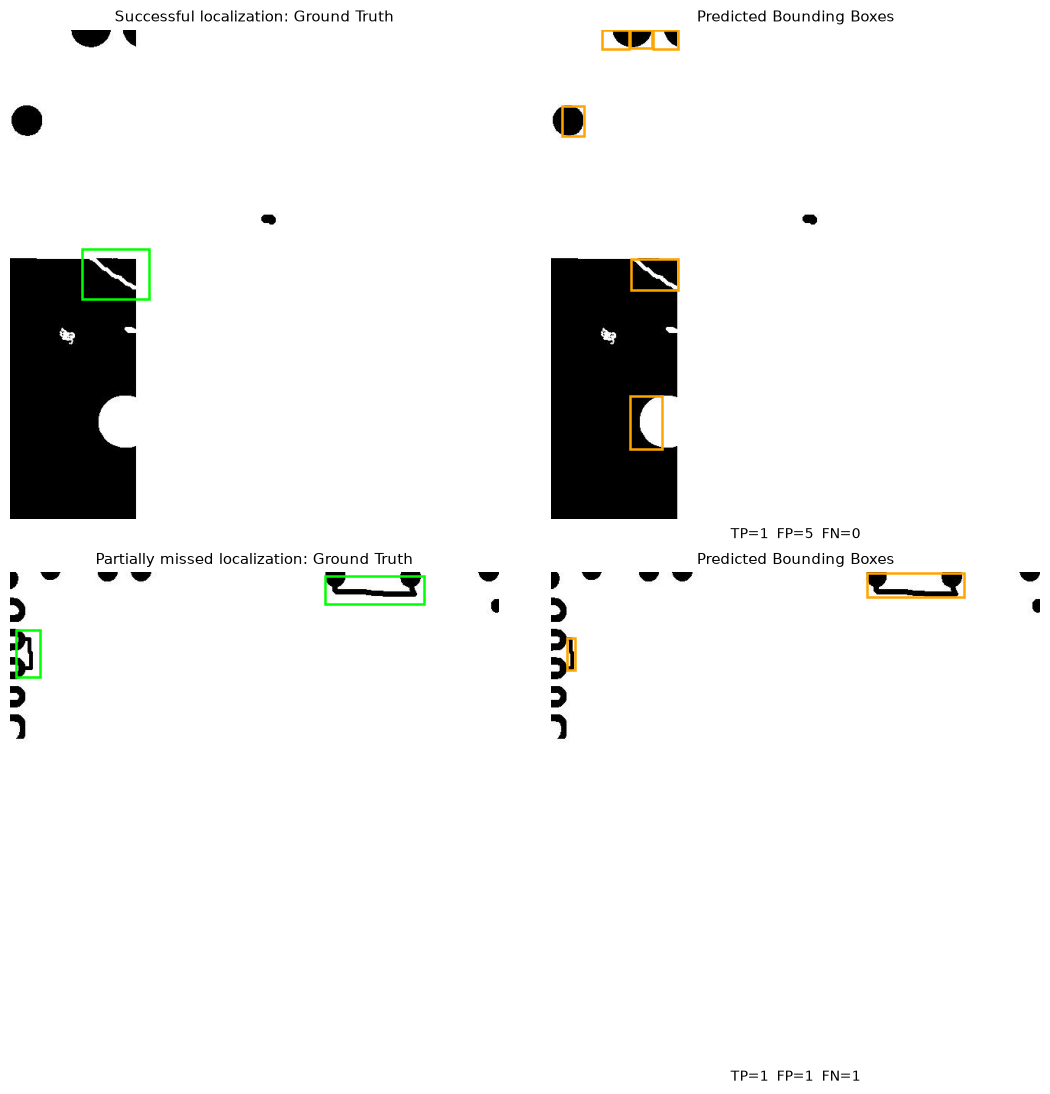

Saved: Role6_Visualization.png
Success image ID: 13000198
Missed image ID: 20085311


In [27]:

import cv2
import runpy
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

# Load the original functions from your teammates
preprocess = runpy.run_path("preprocess (1).py")
detector = runpy.run_path("detection.py")
evaluation = runpy.run_path("evaluate (1).py")

difference = preprocess["difference"]
find_boxes = detector["find_boxes"]
count_matches = evaluation["count_matches"]

root = Path("DeepPCB-master/PCBData")

# Final selected configuration
MIN_AREA = 200
THRESHOLD = 50

def process_sample(line):
    image_rel, annotation_rel = line.split()
    base = root / image_rel

    test_path = base.with_name(base.stem + "_test.jpg")
    temp_path = base.with_name(base.stem + "_temp.jpg")
    annotation_path = root / annotation_rel

    test = cv2.imread(str(test_path), cv2.IMREAD_GRAYSCALE)
    temp = cv2.imread(str(temp_path), cv2.IMREAD_GRAYSCALE)

    if test is None or temp is None:
        raise FileNotFoundError(str(test_path))

    diff = difference(test, temp, blur="none", k=5)

    _, binary = cv2.threshold(
        diff, THRESHOLD, 255, cv2.THRESH_BINARY
    )

    predictions = find_boxes(
        binary, min_area=MIN_AREA, pad=0
    )

    gt = []
    with open(annotation_path, "r") as f:
        for row in f:
            values = row.strip().split()
            if len(values) == 5:
                gt.append(tuple(map(int, values)))

    counts = count_matches(predictions, gt)["Combined"]

    return test, predictions, gt, counts, base.stem


# Find examples from the held-out test split
success = None
missed = None

for line in test_lines:
    sample = process_sample(line)
    counts = sample[3]

    if success is None and counts["TP"] > 0 and counts["FN"] == 0:
        success = sample

    if missed is None and counts["TP"] > 0 and counts["FN"] > 0:
        missed = sample

    if success is not None and missed is not None:
        break

# Fallback if no fully matched example exists
if success is None:
    for line in test_lines:
        sample = process_sample(line)
        if sample[3]["TP"] > 0:
            success = sample
            break

if success is None or missed is None:
    raise ValueError(
        "Suitable examples were not found. "
        "Please inspect the test results."
    )


def draw_boxes(ax, image, boxes, color, title):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    for box in boxes:
        x1, y1, x2, y2 = box[:4]
        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor=color,
            linewidth=1.8
        )
        ax.add_patch(rect)

    ax.set_title(title, fontsize=11)
    ax.axis("off")


fig, axes = plt.subplots(2, 2, figsize=(11, 11))

for row, (sample, label) in enumerate([
    (success, "Successful localization"),
    (missed, "Partially missed localization")
]):
    image, predictions, gt, counts, image_id = sample

    targets = [box for box in gt if box[4] in (1, 2)]

    draw_boxes(
        axes[row, 0], image, targets,
        "lime", f"{label}: Ground Truth"
    )

    draw_boxes(
        axes[row, 1], image, predictions,
        "orange", "Predicted Bounding Boxes"
    )

    axes[row, 1].text(
        0.5, -0.04,
        f"TP={counts['TP']}  FP={counts['FP']}  FN={counts['FN']}",
        transform=axes[row, 1].transAxes,
        ha="center",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    "Role6_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Role6_Visualization.png")
print("Success image ID:", success[4])
print("Missed image ID:", missed[4])


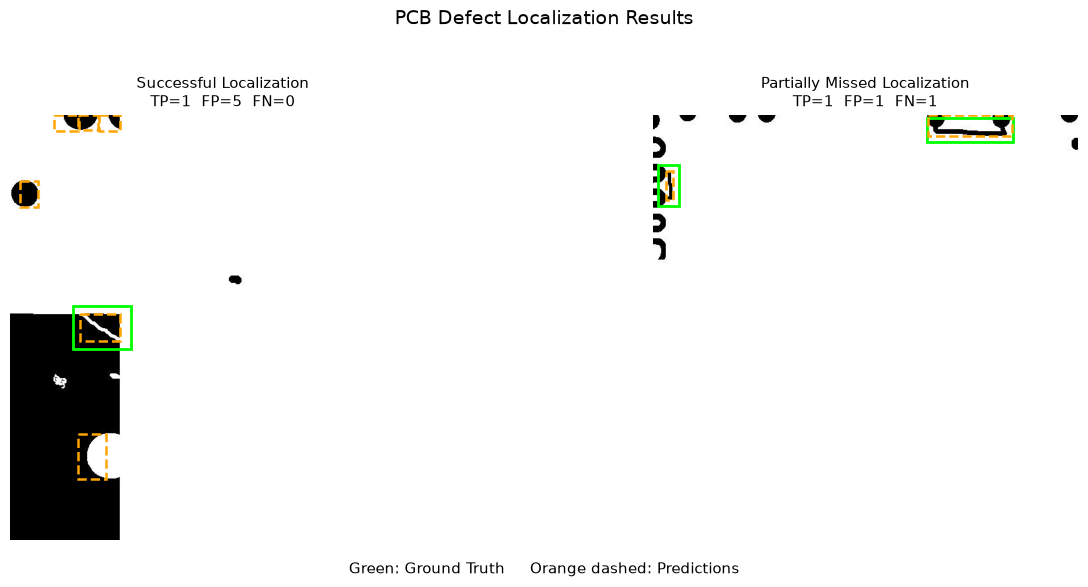

In [28]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, sample, title in zip(
    axes,
    [success, missed],
    ["Successful Localization", "Partially Missed Localization"]
):
    image, predictions, gt, counts, image_id = sample

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    # Ground truth: green
    for box in gt:
        if box[4] in (1, 2):
            x1, y1, x2, y2 = box[:4]
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                fill=False,
                edgecolor="lime",
                linewidth=2
            ))

    # Predictions: orange
    for box in predictions:
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            fill=False,
            edgecolor="orange",
            linewidth=1.8,
            linestyle="--"
        ))

    ax.set_title(
        f"{title}\nTP={counts['TP']}  "
        f"FP={counts['FP']}  FN={counts['FN']}",
        fontsize=11
    )
    ax.axis("off")

fig.suptitle(
    "PCB Defect Localization Results",
    fontsize=14
)

fig.text(
    0.5, 0.04,
    "Green: Ground Truth     Orange dashed: Predictions",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])

plt.savefig(
    "Role6_Final_Figure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
